# Etapa 6 — Análisis de errores de la combinación actualizada

Se conserva el análisis por grosor, zona, grupo clínico y compresión, pero se
evalúan las **máscaras de validación cruzada de `05d`**, actualizadas después
de `05e` y `05f`. Ya no se usa verde con Otsu del 05 inicial.

La candidata combina 26 mapas del verde mediante regresión logística, trabaja
a mitad de resolución y se entrena equilibrando los vasos por grosor.
La regla principal aquí es la fracción elegida en cada vuelta. El valor fijo
se muestra como alternativa; la regla se revisa en la etapa 8.

## Antes de ejecutar

1. Usar la copia completa del repositorio actualizado, incluidos `src`, `models`
   y los notebooks 05b–05f. Conservar los datos `data/raw`.
2. Ejecutar `05d_mascaras_desarrollo.ipynb` **con el código actualizado de 05f**
   para generar nuevamente `results/cache/mascaras_cv`. Si otra persona ya
   lo ejecutó, copiar esa carpeta completa. El ZIP de GitHub no la incluye.
   Si existían máscaras de una versión anterior, deben regenerarse: los
   archivos no contienen una etiqueta de versión que permita distinguirlas.
3. Ejecutar este cuaderno de arriba abajo. No se recalculan filtros ni modelos.

Las máscaras de cada imagen se obtuvieron sin entrenar con su persona.
No usar los pesos entrenados con las 30 imágenes para sustituir esas máscaras.
Las elecciones anteriores se hicieron con desarrollo; esta evaluación no
sustituye la prueba independiente.

Se eliminan las salidas y conclusiones antiguas. Las conclusiones nuevas se
calculan después de ejecutar. Los resultados se guardan en una carpeta nueva.


In [1]:
# En Colab, conectar Drive; fuera de Colab se omite.
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from pathlib import Path
import os
import sys

# Cambiar esta ruta si la copia actualizada tiene otro nombre en Drive.
ROOT = Path('/content/drive/MyDrive/TP-PSI-G8-main')
assert (ROOT / 'src' / 'pipeline.py').exists(), (
    'Revisá ROOT: debe apuntar al repositorio actualizado, que contiene src/pipeline.py.'
)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Proyecto:', ROOT)


Proyecto: /content/drive/MyDrive/TP-PSI-G8-main


In [3]:
import numpy as np
import pandas as pd

from src.config import RESULTS_DIR, WIDTH_LIMITS_PX
from src.data import dev_ids, load_image, load_vessels, load_fov
from src.fov import detect_fov_robust
from src import config as C
from src.pipeline import MASK_CACHE, load_dev_mask
from src.metrics import (
    matthews,
    dice,
    centerline_dice,
    centerline_sensitivity_by_class,
)

# Regla principal: fracción ajustada en cada vuelta de validación.
MASK_KIND = 'combinación'
assert C.SEGMENT_FACTOR == 2
assert len(C.SEGMENT_FEATURES) == 26
assert C.SEGMENT_BALANCED_TRAINING is True, (
    'Esta versión requiere el código/configuración actualizados después de 05f. '
    'Si reemplazaste src con Colab abierto, reiniciá la sesión.'
)

OUT_DIR = RESULTS_DIR / '06_combinacion_equilibrada'
OUT_DIR.mkdir(parents=True, exist_ok=True)

ids = dev_ids()
faltantes = [i for i in ids if not (MASK_CACHE / f'{i}.npz').exists()]
assert not faltantes, (
    f'Faltan máscaras CV: {faltantes}. Ejecutá el 05d actualizado primero '
    'o copiá results/cache/mascaras_cv desde la corrida actualizada.'
)
tipos = ['combinación', 'referencia', 'combinación valor fijo', 'referencia valor fijo']
for i in ids:
    with np.load(MASK_CACHE / f'{i}.npz') as z:
        assert set(tipos).issubset(z.files), f'Máscaras incompletas: {i}'

# Registro de la configuración y de los archivos analizados.
import hashlib
import json
registro = {
    'mascara': MASK_KIND,
    'factor': C.SEGMENT_FACTOR,
    'mapas': C.SEGMENT_FEATURES,
    'entrenamiento_equilibrado': C.SEGMENT_BALANCED_TRAINING,
    'sha256_codigo': {
        n: hashlib.sha256((ROOT / 'src' / n).read_bytes()).hexdigest()
        for n in ['pipeline.py', 'config.py', 'metrics.py']
    },
    'sha256_mascaras': {
        i: hashlib.sha256((MASK_CACHE / f'{i}.npz').read_bytes()).hexdigest()
        for i in ids
    },
}
(OUT_DIR / 'configuracion_analizada.json').write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding='utf-8'
)

filas = []
ids = dev_ids()

for numero, imagen_id in enumerate(ids, start=1):
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    mascara = load_dev_mask(imagen_id, kind=MASK_KIND)
    assert mascara.shape == referencia.shape, f'Tamaño incorrecto: {imagen_id}'

    sensibilidad = centerline_sensitivity_by_class(
        mascara, referencia, WIDTH_LIMITS_PX, region=campo_ref
    )

    filas.append({
        "Imagen": imagen_id,
        "Matthews": matthews(mascara, referencia, campo_ref),
        "Dice": dice(mascara, referencia, campo_ref),
        "Dice línea central": centerline_dice(
            mascara, referencia, campo_ref
        ),
        "Sensibilidad finos": sensibilidad["fino"],
        "Sensibilidad medianos": sensibilidad["mediano"],
        "Sensibilidad gruesos": sensibilidad["grueso"],
    })

    # Checkpoint: una fila por imagen terminada, siempre de esta corrida.
    pd.DataFrame(filas).to_csv(OUT_DIR / '06_errores_por_grosor.csv', index=False)
    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_errores = pd.DataFrame(filas)
tabla_errores.to_csv(
    OUT_DIR / "06_errores_por_grosor.csv", index=False
)

columnas = [
    "Sensibilidad finos",
    "Sensibilidad medianos",
    "Sensibilidad gruesos",
]

display(
    tabla_errores[columnas]
    .mean()
    .rename("Sensibilidad media")
    .to_frame()
    .round(4)
)


1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Sensibilidad media
Sensibilidad finos,0.4040
Sensibilidad medianos,0.8484
Sensibilidad gruesos,0.9336


### Interpretación por grosor

La tabla anterior corresponde a la combinación actualizada. La sensibilidad
es la proporción de la línea central del experto que cae dentro de la predicción.
Los valores antiguos (10,74 % en finos) describían verde con Otsu y no deben
usarse como resultado del método actual.

Como control externo, `05f` informa alrededor del 40 % de sensibilidad en finos
para la combinación equilibrada. La coincidencia se revisa con los valores de
esta corrida, sin copiarlos como resultados ya obtenidos.


## Control de las máscaras importadas

Se verifica Matthews contra las cuatro máscaras del `05d` recibido.
Esto ayuda a detectar cachés equivocadas. Las medias informadas son una
referencia de control, no resultados calculados en este archivo.
La verificación de finos también ayuda a distinguir las máscaras anteriores
al entrenamiento equilibrado, cuyo Matthews era parecido.


In [4]:
filas_control = []
for imagen_id in ids:
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    for tipo in tipos:
        m = load_dev_mask(imagen_id, kind=tipo)
        filas_control.append({
            'Imagen': imagen_id, 'Máscara': tipo,
            'Matthews': matthews(m, referencia, campo_ref),
        })
control = pd.DataFrame(filas_control)
control.to_csv(OUT_DIR / '06_control_mascaras_05d.csv', index=False)
medias_control = control.groupby('Máscara')['Matthews'].mean()
esperadas = pd.Series({
    'combinación': 0.7255, 'referencia': 0.7022,
    'combinación valor fijo': 0.7302, 'referencia valor fijo': 0.7040,
}, name='Media informada en el 05d recibido')
display(pd.concat([medias_control, esperadas], axis=1).round(4))
if (medias_control.sub(esperadas).abs() > 0.001).any():
    print('ATENCIÓN: las máscaras no reproducen el 05d recibido. '
          'Revisá su procedencia antes de interpretar el 06.')
if tabla_errores['Sensibilidad finos'].mean() < 0.37:
    print('ATENCIÓN: la sensibilidad en finos no coincide aproximadamente '
          'con el 40 % informado en 05f. Revisá que 05d se haya vuelto a '
          'ejecutar con entrenamiento equilibrado; no uses cachés antiguas.')


,Matthews,Media informada en el 05d recibido
combinación,0.7255,0.7255
combinación valor fijo,0.7302,0.7302
referencia,0.7022,0.7022
referencia valor fijo,0.7040,0.7040


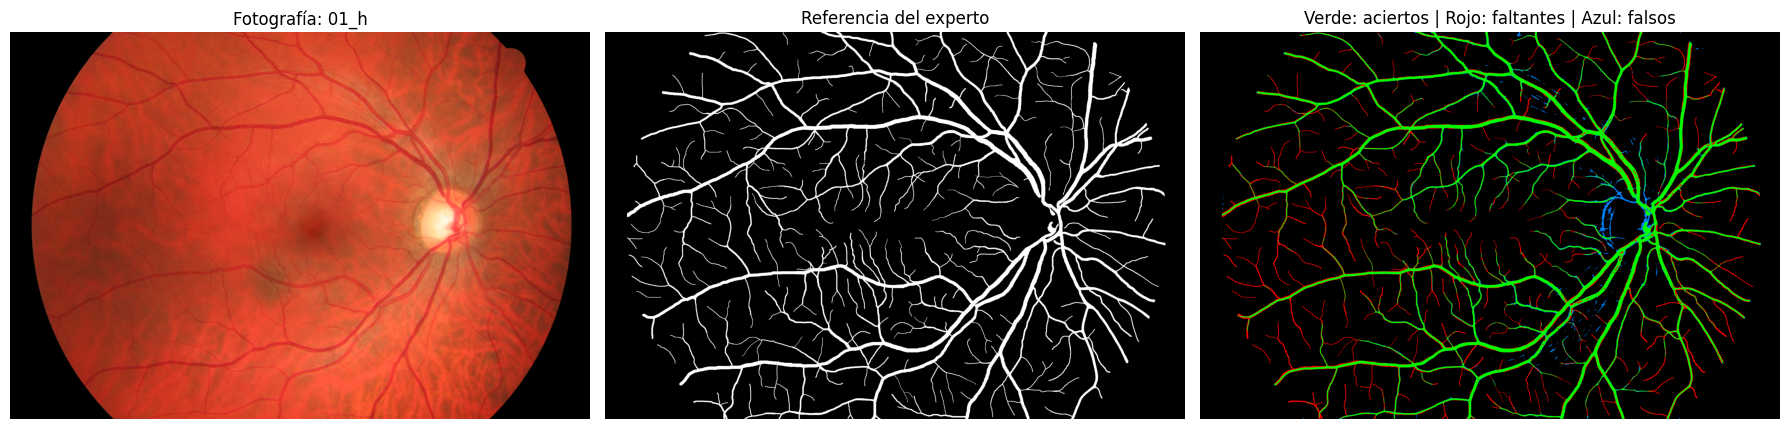

In [5]:
import matplotlib.pyplot as plt

imagen_id = "01_h"

foto = load_image(imagen_id)
referencia = load_vessels(imagen_id).astype(bool)
campo_ref = load_fov(imagen_id).astype(bool)
campo_auto = detect_fov_robust(foto)

mascara = load_dev_mask(imagen_id, kind=MASK_KIND)

aciertos = mascara & referencia & campo_ref
faltantes = ~mascara & referencia & campo_ref
falsos = mascara & ~referencia & campo_ref

errores = np.zeros((*referencia.shape, 3), dtype=np.uint8)
errores[aciertos] = [0, 255, 0]
errores[faltantes] = [255, 0, 0]
errores[falsos] = [0, 130, 255]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(foto)
axes[0].set_title(f"Fotografía: {imagen_id}")

axes[1].imshow(referencia, cmap="gray")
axes[1].set_title("Referencia del experto")

axes[2].imshow(errores)
axes[2].set_title("Verde: aciertos | Rojo: faltantes | Azul: falsos")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Inspección visual: 01_h

Verde indica vasos acertados, rojo vasos omitidos y azul falsas detecciones,
dentro del campo de referencia. Interpretar la imagen nueva: no conservar
la descripción visual de la máscara anterior.


In [6]:
from src.data import load_split

# Recuperamos las métricas guardadas por si se reinició la sesión.
tabla_errores = pd.read_csv(
    OUT_DIR / "06_errores_por_grosor.csv"
)

metadatos = load_split()[
    ["image", "group", "person", "more_compressed"]
]

analisis = tabla_errores.merge(
    metadatos,
    left_on="Imagen",
    right_on="image",
    validate="one_to_one",
)

analisis["Grupo"] = analisis["group"].map({
    "h": "Sanos",
    "dr": "Retinopatía diabética",
    "g": "Glaucoma",
})

# Funciona tanto si la columna se leyó como booleano o como texto.
analisis["Compresión"] = (
    analisis["more_compressed"]
    .astype(str).str.lower()
    .map({"true": "Mayor", "false": "Menor"})
)

assert analisis[["Grupo", "Compresión"]].notna().all().all()

def resumir_grupos(columnas):
    return analisis.groupby(columnas).agg(
        Imagenes=("Imagen", "count"),
        Matthews=("Matthews", "mean"),
        Dice_linea_central=("Dice línea central", "mean"),
        Sensibilidad_finos=("Sensibilidad finos", "mean"),
    ).round(4)

print("Por grupo clínico:")
display(resumir_grupos(["Grupo"]))

print("Por compresión:")
display(resumir_grupos(["Compresión"]))

print("Grupo clínico dentro de cada nivel de compresión:")
display(resumir_grupos(["Compresión", "Grupo"]))

analisis.to_csv(
    OUT_DIR / "06_errores_con_metadatos.csv",
    index=False,
)


Por grupo clínico:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Grupo,,,,
Glaucoma,10,0.7322,0.7331,0.4331
Retinopatía diabética,10,0.6730,0.6692,0.4047
Sanos,10,0.7712,0.8060,0.3743


Por compresión:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Compresión,,,,
Mayor,12,0.7423,0.7623,0.4269
Menor,18,0.7143,0.7186,0.3888


Grupo clínico dentro de cada nivel de compresión:


Imagenes  Matthews  Dice_linea_central  \
Compresión Grupo                                                           
Mayor      Glaucoma                      4    0.7277              0.7400   
           Retinopatía diabética         2    0.6628              0.6639   
           Sanos                         6    0.7786              0.8100   
Menor      Glaucoma                      6    0.7353              0.7285   
           Retinopatía diabética         8    0.6755              0.6705   
           Sanos                         4    0.7602              0.8001   

                                  Sensibilidad_finos  
Compresión Grupo                                      
Mayor      Glaucoma                           0.3977  
           Retinopatía diabética              0.4453  
           Sanos                              0.4402  
Menor      Glaucoma                           0.4568  
           Retinopatía diabética              0.3945  
           Sanos                              0.2756

### Interpretación por grupo y compresión

Comparar las medias nuevas e informar cuántas imágenes hay en cada categoría.
El cruce grupo × compresión permite reconocer categorías pequeñas y la mezcla
entre ambos factores. Las medias por sí solas no atribuyen una causa.
Los intervalos por personas se calculan al final.


## Errores por zona

Se aproxima el centro del disco óptico mediante el máximo de
brillo de la fotografía suavizada dentro del campo automático.

Se define una zona circular con radio de 0,10 veces el diámetro
del campo. Este radio es una decisión exploratoria, no una
medida anatómica validada.

Se compara Matthews cerca de ese centro y en el resto del campo,
sin modificar la segmentación.

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Matthews,Dice
Zona,,
Cerca del disco estimado,0.6962,0.7493
Resto del campo,0.7271,0.7466


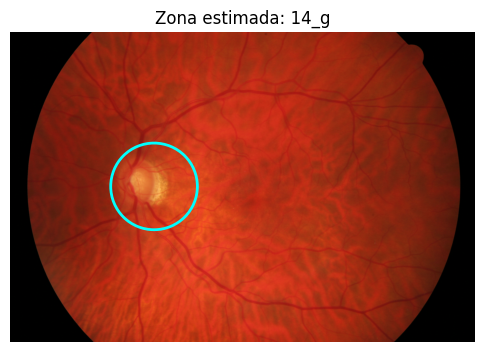

In [7]:
from scipy.ndimage import gaussian_filter
from src.fov import fov_diameter

filas_zonas = []

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id).astype(bool)
    campo_auto = detect_fov_robust(foto)
    diametro = fov_diameter(campo_auto)

    mascara = load_dev_mask(imagen_id, kind=MASK_KIND)

    # Localización aproximada del disco, usando solo la fotografía.
    brillo = foto.astype(np.float32).mean(axis=2)
    suave = gaussian_filter(brillo, sigma=0.02 * diametro)
    suave[~campo_auto] = -np.inf

    cy, cx = np.unravel_index(np.argmax(suave), suave.shape)

    yy, xx = np.ogrid[:referencia.shape[0], :referencia.shape[1]]
    cerca = (yy - cy)**2 + (xx - cx)**2 <= (0.10 * diametro)**2

    for nombre, region in {
        "Cerca del disco estimado": campo_ref & cerca,
        "Resto del campo": campo_ref & ~cerca,
    }.items():
        filas_zonas.append({
            "Imagen": imagen_id,
            "Zona": nombre,
            "Centro x": cx,
            "Centro y": cy,
            "Matthews": matthews(mascara, referencia, region),
            "Dice": dice(mascara, referencia, region),
        })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_zonas = pd.DataFrame(filas_zonas)
tabla_zonas.to_csv(
    OUT_DIR / "06_errores_por_zona.csv", index=False
)

display(
    tabla_zonas.groupby("Zona")[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

# Control visual de la ubicación estimada en la última imagen.
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(foto)
ax.add_patch(
    plt.Circle(
        (cx, cy), 0.10 * diametro,
        fill=False, color="cyan", linewidth=2
    )
)
ax.set_title(f"Zona estimada: {imagen_id}")
ax.axis("off")
plt.show()


### Interpretación por zona

Comparar las medias calculadas con las máscaras nuevas. La región cercana al
disco conserva el radio exploratorio de 0,10 del diámetro del campo; no se
retoca para mejorar el resultado. El máximo de brillo es una localización
aproximada y el control de la última imagen no valida las otras 29.


In [8]:
from src.config import SEED

analisis = pd.read_csv(
    OUT_DIR / "06_errores_con_metadatos.csv"
)

metricas = ["Matthews", "Dice línea central"]
valores = analisis[metricas].to_numpy(dtype=float)

assert np.isfinite(valores).all(), "Hay métricas faltantes."

personas = analisis["person"].unique()
indice_persona = pd.Categorical(
    analisis["person"], categories=personas
).codes

# Cada fila contiene cuántas veces se sorteó cada persona.
rng = np.random.default_rng(SEED)
remuestreos = np.array([
    np.bincount(
        rng.integers(0, len(personas), size=len(personas)),
        minlength=len(personas),
    )
    for _ in range(2000)
])

comparaciones = [
    ("Grupo", "Sanos"),
    ("Grupo", "Retinopatía diabética"),
    ("Grupo", "Glaucoma"),
    ("Compresión", "Mayor"),
]

filas_intervalos = []

for columna, grupo in comparaciones:
    pertenece = analisis[columna].eq(grupo).to_numpy()
    resto = ~pertenece

    diferencia = (
        valores[pertenece].mean(axis=0)
        - valores[resto].mean(axis=0)
    )

    diferencias_boot = []

    for conteos in remuestreos:
        pesos = conteos[indice_persona]

        if pesos[pertenece].sum() == 0 or pesos[resto].sum() == 0:
            continue

        media_grupo = np.average(
            valores[pertenece], axis=0,
            weights=pesos[pertenece],
        )
        media_resto = np.average(
            valores[resto], axis=0,
            weights=pesos[resto],
        )
        diferencias_boot.append(media_grupo - media_resto)

    inferior, superior = np.percentile(
        diferencias_boot, [2.5, 97.5], axis=0
    )

    for j, metrica in enumerate(metricas):
        filas_intervalos.append({
            "Comparación": f"{grupo} frente al resto",
            "Métrica": metrica,
            "Diferencia": diferencia[j],
            "Límite inferior 95%": inferior[j],
            "Límite superior 95%": superior[j],
            "Peor con intervalo bajo cero": superior[j] < 0,
        })

tabla_intervalos = pd.DataFrame(filas_intervalos)

tabla_intervalos.to_csv(
    OUT_DIR / "06_intervalos_subgrupos.csv", index=False
)

display(tabla_intervalos.round(4))


,Comparación,Métrica,Diferencia,Límite inferior 95%,Límite superior 95%,Peor con intervalo bajo cero
0,Sanos frente al resto,Matthews,0.0686,0.0434,0.0987,False
1,Sanos frente al resto,Dice línea central,0.1049,0.0802,0.1368,False
2,Retinopatía diabética frente al resto,Matthews,-0.0787,-0.1128,-0.0475,True
3,Retinopatía diabética frente al resto,Dice línea central,-0.1004,-0.1453,-0.0594,True
4,Glaucoma frente al resto,Matthews,0.0101,-0.0248,0.0510,False
5,Glaucoma frente al resto,Dice línea central,-0.0045,-0.0444,0.0461,False
6,Mayor frente al resto,Matthews,0.0281,-0.0189,0.0739,False
7,Mayor frente al resto,Dice línea central,0.0437,-0.0158,0.1025,False


## Cierre de esta versión

La siguiente celda redacta un resumen numérico usando exclusivamente esta
corrida. Si aparece deterioro en ambas métricas para un subgrupo, se informa
para revisar la regla del plan; no se modifica automáticamente el algoritmo.
Las correcciones anteriores de `05f` ya forman parte de la candidata actual.


In [9]:
from IPython.display import Markdown, display

medias = tabla_errores.select_dtypes(include='number').mean()
grupos = analisis.groupby('Grupo')['Matthews'].mean()
disparadores = tabla_intervalos.groupby('Comparación')[
    'Peor con intervalo bajo cero'
].all()
activos = list(disparadores.index[disparadores])
decision = (
    'Hay deterioro con intervalo bajo cero en ambas métricas para: '
    + ', '.join(activos)
    + '. Revisar la regla de corrección dirigida y lo ya abordado en 05f; '
      'este cuaderno no realiza una corrección adicional.'
    if activos else
    'Ningún subgrupo tiene un intervalo completamente bajo cero en ambas '
    'métricas. No se activa una nueva corrección dirigida por este criterio.'
)
texto = f"""## Resumen calculado de la corrida

- **Máscara:** {MASK_KIND}, guardada con validación por personas en 05d.
- **Matthews medio:** {medias['Matthews']:.4f}.
- **Dice medio:** {medias['Dice']:.4f}.
- **Dice de línea central medio:** {medias['Dice línea central']:.4f}.
- **Sensibilidad de línea central:** finos {medias['Sensibilidad finos']:.1%},
  medianos {medias['Sensibilidad medianos']:.1%},
  gruesos {medias['Sensibilidad gruesos']:.1%}.
- **Menor Matthews por grupo:** {grupos.idxmin()} ({grupos.min():.4f}).

{decision}

Los intervalos son exploratorios, sin ajuste por comparaciones múltiples.
Grupo y compresión están mezclados; las diferencias no demuestran causas.
El disco se localizó de forma aproximada. Las decisiones anteriores usaron
desarrollo: estos resultados no sustituyen la prueba independiente.
"""
display(Markdown(texto))
(OUT_DIR / '06_resumen.md').write_text(texto, encoding='utf-8')


## Resumen calculado de la corrida

- **Máscara:** combinación, guardada con validación por personas en 05d.
- **Matthews medio:** 0.7255.
- **Dice medio:** 0.7468.
- **Dice de línea central medio:** 0.7361.
- **Sensibilidad de línea central:** finos 40.4%,
  medianos 84.8%,
  gruesos 93.4%.
- **Menor Matthews por grupo:** Retinopatía diabética (0.6730).

Hay deterioro con intervalo bajo cero en ambas métricas para: Retinopatía diabética frente al resto. Revisar la regla de corrección dirigida y lo ya abordado en 05f; este cuaderno no realiza una corrección adicional.

Los intervalos son exploratorios, sin ajuste por comparaciones múltiples.
Grupo y compresión están mezclados; las diferencias no demuestran causas.
El disco se localizó de forma aproximada. Las decisiones anteriores usaron
desarrollo: estos resultados no sustituyen la prueba independiente.


867